# v11.1 — Evaluasi 2 kelas (Normal vs AF/AFL)

Versi minor, **evaluasi saja**: tidak ada training baru dan tidak ada paket model yang diubah. Model yang sudah ada (v1 dan v3.1
dari OOF v3; BiGRU, TCN, dan XGBoost v11 dengan bobot kelas lunak = `bawaan` dan bobot penuh = `wp100` / `bobot_penuh`) dinilai
sebagai 2 kelas: AFIB dan AFL digabung menjadi AF/AFL ("AF₁" di literatur).

Protokol sama dengan 3 kelas (AGENTS.md): 5 ulangan × 5 fold pasien, data detektor 50 Hz, metrik pooled OOF rata-rata ulangan,
CI 95% bootstrap pasien 2.000×, berpasangan vs v3.1 dan v1, uji stres takikardia (butir 9), bootstrap bersarang dan tanpa pasien
04936 (butir 10). Dua aturan keputusan dinilai:

| Aturan | Cara |
|---|---|
| `ulang` | p(AF/AFL) = p(AFIB) + p(AFL); **satu** bias AF/AFL dipilih cross-fit (grid −7…+3) untuk Macro-F1 2 kelas. Rencana awal. |
| `gabung` | bias 3 kelas dipilih cross-fit seperti evaluasi biasa, lalu tebakan AFIB dan AFL disatukan. Ditambahkan setelah uji stres aturan `ulang` memperlihatkan alarm baru (analisis tambahan). |

Logika ada di `dua_kelas.py`. Notebook ini menjalankannya (±45 menit CPU lewat `tools/run_notebook.py`, tanpa GPU), menampilkan hasil, dan menulis
`../cache/v11.1/dua_kelas.json` yang dibaca `laporan/build_report.py`.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import dua_kelas as DK
from bersama import data as D

pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)
lama = json.loads(DK.OUT.read_text(encoding="utf-8")) if DK.OUT.exists() else None   # hasil run sebelumnya, jika ada

t0 = time.perf_counter()
res = json.loads(json.dumps(DK.evaluasi(), default=float))                           # bentuk sama dengan file JSON
print(f"selesai {time.perf_counter() - t0:.0f}s → {DK.OUT.relative_to(DK.REPO)}")
G, U = res["aturan"]["gabung"], res["aturan"]["ulang"]
URUT = list(G["sistem"])

aturan ulang: bias 2 kelas dipilih ulang (rencana awal)
  v3.1


  BiGRU bawaan


  BiGRU wp100


  TCN bawaan


  TCN wp100


  XGBoost bawaan


... (5 outputs left out)

  TCN wp100


  XGBoost bawaan


  XGBoost bobot penuh


selesai → /mnt/HDD/03_Akademik_dan_Tugas/WrapSihedaf/cache/v11.1/dua_kelas.json
selesai 2661s → cache/v11.1/dua_kelas.json


Hasilnya deterministik (bootstrap dan bias memakai seed tetap). Jika ada hasil run sebelumnya di cache, semua angkanya
dicocokkan di sini (kecuali info lingkungan).

In [2]:
def datar(x, awal=""):
    if isinstance(x, dict):
        for k, v in x.items():
            yield from datar(v, f"{awal}/{k}")
    elif isinstance(x, list):
        for i, v in enumerate(x):
            yield from datar(v, f"{awal}[{i}]")
    else:
        yield awal, x


def sama(x, y):
    if isinstance(x, float) or isinstance(y, float):
        return (x != x and y != y) or abs(x - y) < 1e-12
    return x == y


if lama is None:
    print("tidak ada hasil sebelumnya untuk dicocokkan")
else:
    a, b = dict(datar(lama)), dict(datar(res))
    beda = sorted(k for k in a.keys() | b.keys()
                  if not k.startswith("/lingkungan") and (k not in a or k not in b or not sama(a[k], b[k])))
    print(f"dicocokkan dengan hasil sebelumnya: {len(b):,} nilai, berbeda: {len(beda)}", beda[:10])

dicocokkan dengan hasil sebelumnya: 4,268 nilai, berbeda: 0 []


## 1. Hasil semua sistem

Macro-F1 3 kelas diambil dari `ringkasan.json` v11 (evaluasi 3 kelas yang sama) sebagai pembanding. Angka dalam kurung siku = CI
95% bootstrap pasien; P = peluang lebih baik pada sampel bootstrap yang sama (≥ 0,95 lebih baik, ≤ 0,05 lebih buruk). v1 tetap
argmax (protokol v1), jadi sama di kedua aturan.

In [3]:
TIGA = {"BiGRU bawaan": "bigru/bawaan", "BiGRU wp100": "bigru/wp100", "TCN bawaan": "tcn/bawaan", "TCN wp100": "tcn/wp100",
        "XGBoost bawaan": "xgboost/bawaan", "XGBoost bobot penuh": "xgboost/bobot_penuh"}
tiga = {}
for n, p in TIGA.items():
    rk = json.loads((D.lokasi_hasil() / p / "ringkasan.json").read_text(encoding="utf-8"))
    tiga[n] = rk["metrik"]["bias"]["Macro-F1"][0]
    tiga.setdefault("v3.1", rk["metrik"]["v31"]["Macro-F1"][0])
    tiga.setdefault("v1 (argmax)", rk["metrik"]["v1"]["Macro-F1"][0])
f3 = lambda m: f"{m[0]:.3f} [{m[1]:.2f}–{m[2]:.2f}]"


def tabel(A):
    rows = []
    for n in URUT:
        s = A["sistem"][n]
        v31, v1 = s.get("vs_v31", {}).get("Macro-F1"), s.get("vs_v1", {}).get("Macro-F1")
        rows.append({"sistem": n, "Macro-F1 3 kelas": round(tiga[n], 3), "Macro-F1 2 kelas": f3(s["Macro-F1"]),
                     "F1 AF/AFL": f3(s["F1 AF1"]), "Se": round(s["Se"][0], 3), "Sp": round(s["Sp"][0], 3), "PPV": round(s["PPV"][0], 3),
                     "vs v3.1 Δ (P)": f"{v31[0]:+.3f} ({v31[3]:.2f})" if v31 else "–",
                     "vs v1 Δ (P)": f"{v1[0]:+.3f} ({v1[3]:.2f})" if v1 else "–"})
    return pd.DataFrame(rows).set_index("sistem")


for a in ("gabung", "ulang"):
    print(f"=== aturan {a}: {res['keterangan_aturan'][a]}")
    display(tabel(res["aturan"][a]))

bias = {n: {"gabung: bias AFIB / AFL (median)": "{:+.2f} / {:+.2f}".format(*G["sistem"][n]["bias"]["median"]),
            "gabung: di batas grid": f"{G['sistem'][n]['bias']['di_batas']:.0%}",
            "ulang: bias AF/AFL median [min…maks]": "{median:+.2f} [{min:+.2f}…{maks:+.2f}]".format(**U["sistem"][n]["bias"]),
            "ulang: di batas grid": f"{U['sistem'][n]['bias']['di_batas']:.0%}"} for n in URUT if "bias" in G["sistem"][n]}
display(pd.DataFrame(bias).T)

=== aturan gabung: bias 3 kelas, lalu AFIB + AFL digabung (tambahan)


,Macro-F1 3 kelas,Macro-F1 2 kelas,F1 AF/AFL,Se,Sp,PPV,vs v3.1 Δ (P),vs v1 Δ (P)
sistem,,,,,,,,
v1 (argmax),0.744,0.922 [0.88–0.95],0.910 [0.87–0.94],0.954,0.903,0.870,-0.004 (0.20),–
v3.1,0.832,0.926 [0.88–0.95],0.913 [0.87–0.94],0.934,0.924,0.892,–,+0.004 (0.81)
BiGRU bawaan,0.821,0.938 [0.91–0.96],0.926 [0.90–0.95],0.926,0.950,0.926,+0.012 (1.00),+0.016 (0.98)
BiGRU wp100,0.830,0.934 [0.90–0.96],0.922 [0.89–0.95],0.938,0.935,0.907,+0.009 (1.00),+0.012 (1.00)
TCN bawaan,0.752,0.933 [0.91–0.95],0.919 [0.89–0.94],0.902,0.959,0.937,+0.008 (0.74),+0.011 (0.83)
TCN wp100,0.830,0.935 [0.91–0.96],0.922 [0.89–0.95],0.919,0.950,0.926,+0.010 (0.86),+0.013 (0.92)
XGBoost bawaan,0.730,0.916 [0.87–0.95],0.899 [0.86–0.94],0.901,0.931,0.898,-0.010 (0.07),-0.006 (0.26)
XGBoost bobot penuh,0.744,0.916 [0.87–0.95],0.901 [0.86–0.94],0.905,0.929,0.896,-0.009 (0.05),-0.005 (0.26)


=== aturan ulang: bias 2 kelas dipilih ulang (rencana awal)


,Macro-F1 3 kelas,Macro-F1 2 kelas,F1 AF/AFL,Se,Sp,PPV,vs v3.1 Δ (P),vs v1 Δ (P)
sistem,,,,,,,,
v1 (argmax),0.744,0.922 [0.88–0.95],0.910 [0.87–0.94],0.954,0.903,0.870,+0.005 (0.84),–
v3.1,0.832,0.916 [0.87–0.94],0.902 [0.86–0.93],0.928,0.913,0.878,–,-0.005 (0.16)
BiGRU bawaan,0.821,0.938 [0.91–0.96],0.927 [0.90–0.95],0.940,0.940,0.914,+0.022 (1.00),+0.016 (1.00)
BiGRU wp100,0.830,0.924 [0.89–0.95],0.911 [0.87–0.94],0.934,0.921,0.889,+0.008 (0.97),+0.002 (0.67)
TCN bawaan,0.752,0.938 [0.91–0.96],0.927 [0.90–0.95],0.941,0.939,0.913,+0.022 (1.00),+0.016 (0.99)
TCN wp100,0.830,0.932 [0.90–0.95],0.919 [0.89–0.94],0.936,0.932,0.903,+0.015 (0.99),+0.010 (0.90)
XGBoost bawaan,0.730,0.919 [0.87–0.95],0.906 [0.86–0.94],0.929,0.917,0.883,+0.003 (0.73),-0.002 (0.36)
XGBoost bobot penuh,0.744,0.918 [0.87–0.95],0.904 [0.86–0.94],0.928,0.915,0.881,+0.002 (0.63),-0.004 (0.27)


,gabung: bias AFIB / AFL (median),gabung: di batas grid,ulang: bias AF/AFL median [min…maks],ulang: di batas grid
v3.1,-0.75 / -4.50,0%,-0.75 [-1.25…+0.25],0%
BiGRU bawaan,-0.75 / -2.00,0%,-0.50 [-1.00…+0.25],0%
BiGRU wp100,-0.50 / -4.00,0%,-0.75 [-1.25…+0.25],0%
TCN bawaan,-1.50 / -3.00,0%,-0.50 [-1.25…+0.50],0%
TCN wp100,-1.00 / -5.25,0%,-0.75 [-1.50…+0.25],0%
XGBoost bawaan,-0.75 / +0.00,0%,+0.00 [-0.50…+1.25],0%
XGBoost bobot penuh,-0.75 / -2.00,2%,-0.25 [-0.75…+1.00],0%


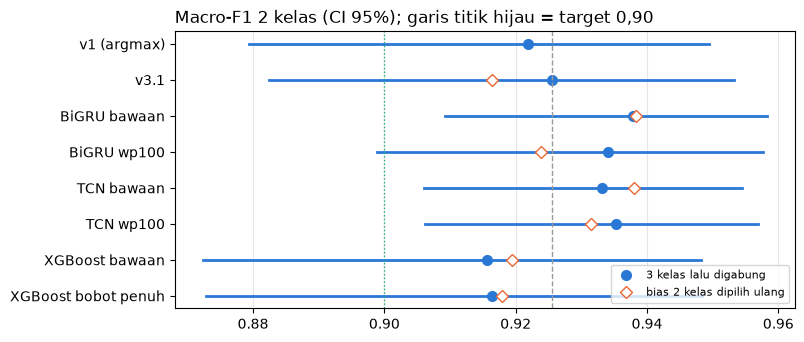

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, n in enumerate(URUT):
    pt, lo, hi = G["sistem"][n]["Macro-F1"]
    ax.plot([lo, hi], [i, i], color="#2a78d6", lw=2)
    ax.plot(pt, i, "o", color="#2a78d6", ms=7, label="3 kelas lalu digabung" if i == 0 else None)
    if n != "v1 (argmax)":
        ax.plot(U["sistem"][n]["Macro-F1"][0], i, "D", color="#eb6834", mfc="white", ms=6, label="bias 2 kelas dipilih ulang" if i == 1 else None)
ax.axvline(G["sistem"]["v3.1"]["Macro-F1"][0], color="0.6", ls="--", lw=1)
ax.axvline(0.90, color="#1baf7a", ls=":", lw=1)
ax.set_yticks(range(len(URUT)), URUT); ax.invert_yaxis(); ax.grid(axis="x", color="0.9")
ax.set_title("Macro-F1 2 kelas (CI 95%); garis titik hijau = target 0,90", loc="left"); ax.legend(loc="lower right", fontsize=8)
plt.show()

## 2. Alarm pada ritme normal (butir 9)

Bagian window Normal asli yang menjadi alarm AF/AFL per pita detak, ditambah window Normal yang **teratur** di 80–95 bpm
(CV IBI < 0,03) dan sisanya di pita yang sama. Ambang uji stres sintetis = detak terendah di mana < 50% ritme teratur sintetis
ditebak Normal (tanpa variasi / seragam ±10 ms / Gauss 10 ms / Gauss 20 ms). Model v11 menyimpan prediksi uji stres per fold;
v3.1 diwakili kontrol v7 (resep v3.1, ulangan 0).

In [5]:
def ambang(s):
    st = s.get("stres") or s.get("stres_kontrol_v7")
    return " / ".join(str(int(v)) for v in st["ambang"].values()) if st else "–"


rows = []
for n in URUT:
    g, u = G["sistem"][n], U["sistem"][n]
    rows.append({"sistem": n, **{f"Normal {k}": f"{v:.1%}" for k, v in g["alarm_normal"].items()},
                 "teratur 80–95 (gabung / ulang)": f"{g['teratur_80_95']:.1%} / {u['teratur_80_95']:.1%}",
                 "lain 80–95 (gabung / ulang)": f"{g['lain_80_95']:.1%} / {u['lain_80_95']:.1%}",
                 "ambang sintetis gabung": ambang(g), "ambang sintetis ulang": ambang(u)})
display(pd.DataFrame(rows).set_index("sistem"))
print("window Normal per pita:", res["n"]["normal_per_pita"], "| teratur 80–95:", res["n"]["teratur_80_95"],
      "| lain 80–95:", res["n"]["lain_80_95"])

,Normal < 100,Normal 100–110,Normal 110–120,Normal ≥ 120,teratur 80–95 (gabung / ulang),lain 80–95 (gabung / ulang),ambang sintetis gabung,ambang sintetis ulang
sistem,,,,,,,,
v1 (argmax),8.8%,14.2%,66.2%,94.4%,0.3% / 0.3%,43.0% / 43.0%,–,–
v3.1,6.7%,12.7%,59.0%,95.2%,0.1% / 18.6%,35.6% / 38.5%,120 / 120 / 120 / 115,115 / 115 / 115 / 115
BiGRU bawaan,4.1%,10.0%,52.6%,86.6%,0.1% / 6.2%,22.9% / 25.6%,120 / 120 / 120 / 120,115 / 115 / 115 / 115
BiGRU wp100,5.5%,12.2%,60.5%,90.2%,0.0% / 22.4%,28.9% / 31.7%,120 / 120 / 120 / 115,85 / 85 / 85 / 110
TCN bawaan,3.4%,7.7%,43.1%,71.8%,0.9% / 6.9%,17.4% / 24.8%,120 / 125 / 130 / 130,115 / 115 / 85 / 115
TCN wp100,4.2%,9.5%,49.5%,84.4%,0.5% / 18.7%,20.8% / 25.5%,125 / 125 / 125 / 120,115 / 115 / 85 / 110
XGBoost bawaan,6.0%,12.0%,56.0%,85.0%,1.6% / 2.2%,32.7% / 39.1%,125 / 120 / 115 / 115,125 / 115 / 115 / 110
XGBoost bobot penuh,6.2%,12.4%,54.9%,82.8%,1.8% / 3.6%,34.0% / 40.0%,125 / 120 / 120 / 115,125 / 120 / 115 / 110


window Normal per pita: {'< 100': 89566, '100–110': 8766, '110–120': 568, '≥ 120': 100} | teratur 80–95: 4968 | lain 80–95: 8402


Asal alarm 80–95 bpm pada aturan `ulang`: window **AFL** yang teratur di pita yang sama. Model belajar bahwa ritme teratur di
sekitar 85–90 bpm bisa AFL. Bias 3 kelas menekan AFL kuat, sedangkan satu bias AF/AFL tidak punya penekan itu.

window AFL teratur 80–95 bpm: 113 dari 1152 window AFL; per pasien {'04936': 109, '08215': 4}; detak persentil 5–95: [84.4 91.6]


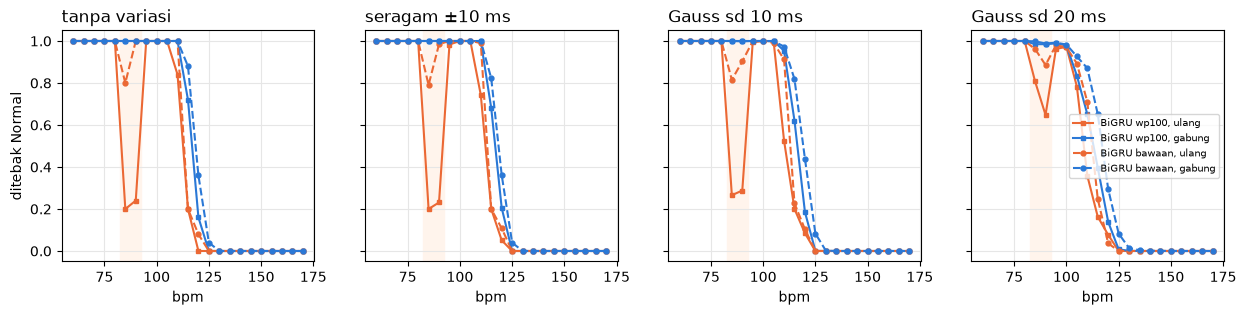

In [6]:
d = D.muat()
ibi, msk = d.X[..., 0], d.M.astype(bool)
cv_ibi = np.array([ibi[i][msk[i]].std() / ibi[i][msk[i]].mean() for i in range(len(ibi))])
lambat = (d.y == 2) & (d.hr >= 80) & (d.hr < 95) & (cv_ibi < 0.03)
asal_afl = {str(p): int((lambat & (d.records == p)).sum()) for p in np.unique(d.records[lambat])}
print(f"window AFL teratur 80–95 bpm: {lambat.sum()} dari {(d.y == 2).sum()} window AFL; per pasien {asal_afl}; "
      f"detak persentil 5–95: {np.percentile(d.hr[lambat], [5, 95]).round(1)}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, j in zip(axes, G["sistem"]["BiGRU wp100"]["stres"]["proporsi_normal"]):
    for n, mk in (("BiGRU wp100", "s"), ("BiGRU bawaan", "o")):
        for A, col, lab in ((U, "#eb6834", "ulang"), (G, "#2a78d6", "gabung")):
            st = A["sistem"][n]["stres"]
            ax.plot(st["bpm"], st["proporsi_normal"][j], marker=mk, ms=3.5, color=col, ls="-" if n == "BiGRU wp100" else "--",
                    label=f"{n}, {lab}")
    ax.axvspan(82.5, 92.5, color="#FFF4EC", zorder=0); ax.set_title(j, loc="left"); ax.set_xlabel("bpm"); ax.grid(color="0.9")
axes[0].set_ylabel("ditebak Normal"); axes[-1].legend(fontsize=7)
plt.show()

## 3. Uji paling ketat (butir 10)

**Bootstrap bersarang**: di setiap sampel bootstrap, bias dipilih ulang pada pasien latih yang terambil (aturan `gabung`: bias 3
kelas dengan Macro-F1 3 kelas; aturan `ulang`: satu bias AF/AFL), lalu dipasang ke pasien uji. **Tanpa 04936**: window pasien itu
dikeluarkan dari evaluasi dan bias dihitung ulang di 22 pasien (model tidak dilatih ulang).

In [7]:
rows = []
for n, g in G["bersarang"].items():
    u = U["bersarang"][n]
    rows.append({"sistem": n, "gabung: Macro-F1 [CI]": f"{g['titik']:.3f} [{g['ci'][0]:.2f}–{g['ci'][1]:.2f}]",
                 "gabung: vs v1 Δ (P)": f"{g['vs_v1']['delta']:+.3f} ({g['vs_v1']['p']:.3f})",
                 "gabung: vs v3.1 Δ (P)": f"{g['vs_v31']['delta']:+.3f} ({g['vs_v31']['p']:.3f})" if "vs_v31" in g else "–",
                 "ulang: P vs v1 / v3.1": f"{u['vs_v1']['p']:.3f} / " + (f"{u['vs_v31']['p']:.3f}" if "vs_v31" in u else "–")})
print("Bootstrap bersarang"); display(pd.DataFrame(rows).set_index("sistem"))

rows = []
for n in URUT:
    g, u = G["tanpa_04936"][n], U["tanpa_04936"][n]
    v31 = g.get("vs_v31", {}).get("Macro-F1")
    rows.append({"sistem": n, "gabung: Macro-F1": f3(g["Macro-F1"]), "gabung: Se / Sp": f"{g['Se'][0]:.3f} / {g['Sp'][0]:.3f}",
                 "gabung: vs v3.1 Δ (P)": f"{v31[0]:+.3f} ({v31[3]:.2f})" if v31 else "–", "ulang: Macro-F1": round(u["Macro-F1"][0], 3)})
print(f"Tanpa {DK.PASIEN_TANPA} ({res['n']['pasien_tanpa']} pasien)"); display(pd.DataFrame(rows).set_index("sistem"))

Bootstrap bersarang


,gabung: Macro-F1 [CI],gabung: vs v1 Δ (P),gabung: vs v3.1 Δ (P),ulang: P vs v1 / v3.1
sistem,,,,
v3.1,0.926 [0.87–0.95],+0.004 (0.520),–,0.090 / –
BiGRU bawaan,0.938 [0.90–0.96],+0.016 (0.979),+0.012 (0.962),0.989 / 1.000
BiGRU wp100,0.934 [0.89–0.96],+0.012 (0.959),+0.009 (0.956),0.473 / 0.951
TCN bawaan,0.933 [0.90–0.95],+0.011 (0.889),+0.008 (0.852),0.976 / 1.000
TCN wp100,0.935 [0.90–0.96],+0.013 (0.941),+0.010 (0.928),0.814 / 0.978
XGBoost bawaan,0.916 [0.86–0.95],-0.006 (0.121),-0.010 (0.100),0.206 / 0.697
XGBoost bobot penuh,0.916 [0.86–0.95],-0.005 (0.124),-0.009 (0.089),0.155 / 0.623


Tanpa 04936 (22 pasien)


,gabung: Macro-F1,gabung: Se / Sp,gabung: vs v3.1 Δ (P),ulang: Macro-F1
sistem,,,,
v1 (argmax),0.922 [0.88–0.95],0.959 / 0.902,-0.005 (0.15),0.922
v3.1,0.927 [0.88–0.95],0.933 / 0.928,–,0.917
BiGRU bawaan,0.938 [0.91–0.96],0.918 / 0.956,+0.011 (0.92),0.940
BiGRU wp100,0.933 [0.90–0.96],0.931 / 0.940,+0.006 (0.91),0.924
TCN bawaan,0.937 [0.91–0.96],0.907 / 0.962,+0.010 (0.81),0.939
TCN wp100,0.936 [0.91–0.96],0.913 / 0.956,+0.009 (0.85),0.932
XGBoost bawaan,0.918 [0.88–0.95],0.895 / 0.939,-0.009 (0.04),0.922
XGBoost bobot penuh,0.919 [0.88–0.95],0.900 / 0.937,-0.008 (0.09),0.922


## 4. Per pasien (aturan `gabung`)

Sensitivitas AF/AFL dan bagian window Normal yang menjadi alarm, dijumlah 5 ulangan. `NaN` = pasien tidak punya window kelas itu.

In [8]:
pp = G["per_pasien"]
pilih = ["v3.1", "BiGRU bawaan", "BiGRU wp100", "TCN bawaan", "TCN wp100"]
display(pd.concat({"sensitivitas AF/AFL": pd.DataFrame({n: pp[n]["se"] for n in pilih}, index=res["pasien"]),
                   "Normal → alarm": pd.DataFrame({n: pp[n]["alarm_normal"] for n in pilih}, index=res["pasien"])}, axis=1).round(2))

sensitivitas AF/AFL                                               Normal → alarm                                              
                     v3.1 BiGRU bawaan BiGRU wp100 TCN bawaan TCN wp100           v3.1 BiGRU bawaan BiGRU wp100 TCN bawaan TCN wp100
04015                1.00         0.97        1.00       1.00      1.00           0.09         0.07        0.08       0.07      0.08
04043                0.98         0.97        0.98       0.96      0.98           0.05         0.04        0.04       0.03      0.03
04048                0.98         0.97        1.00       0.90      0.96           0.03         0.02        0.03       0.02      0.03
04126                0.95         0.92        0.98       0.87      0.90           0.07         0.05        0.08       0.05      0.06
04746                0.96         0.96        0.97       0.95      0.97           0.01         0.00        0.00       0.00      0.00
04908                0.99         0.98        0.99       0.98      0.99           0.01         0.00        0.01       0.00      0.00
04936                0.85         0.86        0.88       0.77      0.84           0.02         0.01        0.01       0.01      0.01
05091                0.93         0.93        0.93       0.76      0.80           0.02         0.01        0.01       0.00      0.01
05121                0.90         0.91        0.91       0.89      0.90           0.04         0.04        0.04       0.03      0.04
05261                0.99         0.92        0.98       0.90      0.96           0.05         0.03        0.04       0.03      0.04
06426                0.97         0.95        0.95       0.93      0.95           0.28         0.23        0.25       0.22      0.24
06453                0.74         0.67        0.73       0.63      0.69           0.06         0.01        0.03       0.01      0.02
06995                0.95         0.97        0.97       0.96      0.96           0.23         0.22        0.21       0.17      0.19
07162                0.91         0.88        0.89       0.83      0.81            NaN          NaN         NaN        NaN       NaN
07859                0.88         0.87        0.92       0.83      0.89            NaN          NaN         NaN        NaN       NaN
07879                0.99         0.99        0.99       0.99      0.99           0.05         0.04        0.05       0.03      0.03
07910                0.94         0.94        0.94       0.92      0.94           0.02         0.01        0.02       0.01      0.02
08215                0.89         0.89        0.89       0.89      0.88           0.01         0.01        0.01       0.00      0.01
08219                0.98         0.97        0.98       0.96      0.97           0.60         0.35        0.49       0.26      0.33
08378                0.93         0.93        0.94       0.87      0.91           0.00         0.00        0.00       0.00      0.00
08405                0.99         0.97        0.98       0.98      0.98           0.01         0.00        0.01       0.01      0.01
08434                0.98         0.98        0.99       0.98      0.99           0.01         0.00        0.01       0.00      0.01
08455                0.99         0.99        0.99       0.98      0.99           0.00         0.00        0.00       0.00      0.00

## 5. Cek angka kesimpulan

Angka yang dikutip di Kesimpulan dicocokkan dengan hasil run ini (dibulatkan seperti di teks).

In [9]:
SG, SU, BG, TG = G["sistem"], U["sistem"], G["bersarang"], G["tanpa_04936"]
model = [n for n in URUT if n not in ("v1 (argmax)", "v3.1")]
cek = [
    ("Macro-F1 2 kelas terendah", min(SG[n]["Macro-F1"][0] for n in URUT), 0.916, 3),
    ("Macro-F1 2 kelas tertinggi", max(SG[n]["Macro-F1"][0] for n in URUT), 0.938, 3),
    ("terbaik = BiGRU bawaan", float(max(model, key=lambda n: SG[n]["Macro-F1"][0]) == "BiGRU bawaan"), 1.0, 0),
    ("Macro-F1 3 kelas terendah", min(tiga.values()), 0.730, 3),
    ("Macro-F1 3 kelas tertinggi", max(tiga.values()), 0.832, 3),
    ("v3.1 2 kelas", SG["v3.1"]["Macro-F1"][0], 0.926, 3),
    ("BiGRU bawaan Δ vs v3.1", SG["BiGRU bawaan"]["vs_v31"]["Macro-F1"][0], 0.012, 3),
    ("BiGRU bawaan P vs v3.1", SG["BiGRU bawaan"]["vs_v31"]["Macro-F1"][3], 1.00, 2),
    ("BiGRU wp100 Δ vs v3.1", SG["BiGRU wp100"]["vs_v31"]["Macro-F1"][0], 0.009, 3),
    ("BiGRU wp100 P vs v3.1", SG["BiGRU wp100"]["vs_v31"]["Macro-F1"][3], 1.00, 2),
    ("TCN bawaan P vs v3.1", SG["TCN bawaan"]["vs_v31"]["Macro-F1"][3], 0.74, 2),
    ("TCN wp100 P vs v3.1", SG["TCN wp100"]["vs_v31"]["Macro-F1"][3], 0.86, 2),
    ("BiGRU bawaan bersarang P vs v1", BG["BiGRU bawaan"]["vs_v1"]["p"], 0.98, 2),
    ("BiGRU bawaan bersarang P vs v3.1", BG["BiGRU bawaan"]["vs_v31"]["p"], 0.96, 2),
    ("BiGRU wp100 bersarang P vs v1", BG["BiGRU wp100"]["vs_v1"]["p"], 0.96, 2),
    ("BiGRU wp100 bersarang P vs v3.1", BG["BiGRU wp100"]["vs_v31"]["p"], 0.96, 2),
    ("tanpa 04936 terendah", min(TG[n]["Macro-F1"][0] for n in URUT), 0.918, 3),
    ("tanpa 04936 tertinggi", max(TG[n]["Macro-F1"][0] for n in URUT), 0.938, 3),
    ("tanpa 04936 BiGRU bawaan P vs v3.1", TG["BiGRU bawaan"]["vs_v31"]["Macro-F1"][3], 0.92, 2),
    ("tanpa 04936 BiGRU wp100 P vs v3.1", TG["BiGRU wp100"]["vs_v31"]["Macro-F1"][3], 0.91, 2),
    ("ulang: teratur 80–95 v3.1 (%)", SU["v3.1"]["teratur_80_95"] * 100, 18.6, 1),
    ("ulang: teratur 80–95 BiGRU wp100 (%)", SU["BiGRU wp100"]["teratur_80_95"] * 100, 22.4, 1),
    ("gabung: teratur 80–95 tertinggi (%)", max(SG[n]["teratur_80_95"] for n in URUT) * 100, 1.8, 1),
    ("ulang: ambang sintetis BiGRU wp100 (tanpa variasi)", SU["BiGRU wp100"]["stres"]["ambang"]["tanpa variasi"], 85, 0),
    ("window AFL teratur 80–95 bpm", float(lambat.sum()), 113, 0),
    ("… dari 04936", asal_afl["04936"], 109, 0),
    ("Normal ≥ 120 → alarm, v3.1 (%)", SG["v3.1"]["alarm_normal"]["≥ 120"] * 100, 95.2, 1),
    ("Normal ≥ 120 → alarm, BiGRU bawaan (%)", SG["BiGRU bawaan"]["alarm_normal"]["≥ 120"] * 100, 86.6, 1),
    ("Normal ≥ 120 → alarm, TCN bawaan (%)", SG["TCN bawaan"]["alarm_normal"]["≥ 120"] * 100, 71.8, 1),
]
for nama, nilai, tertulis, nd in cek:
    assert round(nilai, nd) == tertulis, (nama, nilai, tertulis)
print(f"✓ {len(cek)} angka kesimpulan cocok dengan hasil run")

✓ 29 angka kesimpulan cocok dengan hasil run


## 6. Kesimpulan

**Target Macro-F1 ≥ 0,90 tercapai untuk tugas 2 kelas (Normal vs AF/AFL) di semua sistem: 0,916–0,938.** Untuk model yang sama,
Macro-F1 3 kelas 0,730–0,832; selisihnya hampir seluruhnya kelas AFL. Paket produksi tetap v3.1.

- **Hasil (aturan `gabung`).**
  - Terbaik **BiGRU bawaan 0,938** [0,91–0,96]. v3.1 0,926.
  - Lebih baik dari v3.1: BiGRU bawaan (+0,012, P = 1,00) dan BiGRU wp100 (+0,009, P = 1,00), terutama karena spesifisitas
    lebih tinggi. TCN tidak terbedakan (P = 0,74 / 0,86).
- **Butir 10.**
  - Bootstrap bersarang: BiGRU bawaan lebih baik dari v1 (P = 0,98) dan v3.1 (P = 0,96); BiGRU wp100 0,96 / 0,96.
  - Tanpa 04936: Macro-F1 semua sistem tetap 0,918–0,938, jadi tingginya angka 2 kelas tidak bergantung pada satu pasien. Namun
    keunggulan atas v3.1 tidak lagi pasti (BiGRU bawaan P = 0,92, BiGRU wp100 P = 0,91).
- **Aturan keputusan menentukan alarm palsu baru (temuan setelah melihat hasil).**
  - Dengan aturan `ulang`, window Normal teratur 80–95 bpm yang menjadi alarm: 18,6% (v3.1) dan 22,4% (BiGRU wp100). Ambang uji
    sintetis BiGRU wp100 turun ke 85 bpm.
  - Sumbernya 113 window AFL teratur di 80–95 bpm (109 dari 04936). Aturan `gabung` menahan alarm itu di ≤ 1,8% dengan
    Macro-F1 yang hampir sama. **Keluaran 2 kelas harus diambil dari keputusan 3 kelas lalu digabung.**
- **Takikardia tetap masalah (butir 9).** Window Normal ≥ 120 bpm yang menjadi alarm: 95,2% (v3.1), 86,6% (BiGRU bawaan),
  71,8% (TCN bawaan). Menggabungkan kelas tidak memisahkan ritme cepat-teratur dari aritmia.

**Langkah berikutnya:** laporkan Macro-F1 2 kelas berdampingan dengan 3 kelas. BiGRU bawaan adalah kandidat keluaran 2 kelas,
tetapi belum dikemas. Mengganti paket produksi butuh keputusan produk (2 vs 3 kelas) dan solusi alarm takikardia ≥ 120 bpm.
Laporan: `laporan/laporan_dua_kelas.pdf`.